# B 站二维码登录接口行为实测(独立脚本,不依赖项目)

目的:验证 [docs/zoku-issue-qrcode-login.md](zoku-issue-qrcode-login.md) 中记录的接口行为,
用于给 bilibili-api-zoku 提 issue 时提供实测依据。

> ⚠️ **安全提醒**:本 notebook 的输出包含你的登录凭证(SESSDATA 等),
> **不要提交到 git / 不要分享给别人**;跑完可在 Notebook 菜单清除输出。

依赖(与项目无关,任何环境可跑):
```
pip install curl_cffi qrcode ipykernel
```
项目 uv 环境里这两个包已存在(zoku 的依赖),可直接选 .venv 内核。

In [14]:
# 同步 Session:跨 cell 复用,自动累积 cookies;impersonate 伪装浏览器指纹
from curl_cffi.requests import Session

s = Session(impersonate="chrome")
print("session ready")

session ready


generate 响应 code: 0
qrcode_key: f3a8792438961437a8cf13d95d0354ff


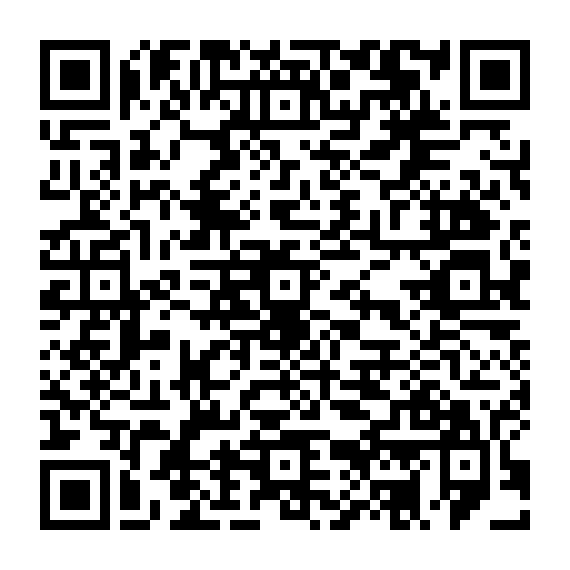

In [15]:
# 1. 生成二维码:POST /x/passport-login/web/qrcode/generate
import io
import qrcode
from IPython.display import display, Image

resp = s.get("https://passport.bilibili.com/x/passport-login/web/qrcode/generate")
body = resp.json()
print("generate 响应 code:", body.get("code"))

data = body.get("data") or {}
qr_key = data.get("qrcode_key")
print("qrcode_key:", qr_key)

# data.url 是二维码要编码的内容,本地生成 PNG 显示
img = qrcode.make(data.get("url"))
buf = io.BytesIO()
img.save(buf, format="PNG")
display(Image(data=buf.getvalue()))

用**手机 bilibili App 扫码**并确认,然后跑下一个 cell。

In [17]:
# 2. 轮询状态:GET /qrcode/getLoginInfo?qrcode_key=xxx
#    响应两层结构:外层 code=请求级,内层 data.code=二维码状态
import time

POLL_URL = "https://passport.bilibili.com/x/passport-login/web/qrcode/poll"
prev = None
result = None
for i in range(90):  # 2s 间隔,最长 3 分钟
    r = s.get(POLL_URL, params={"qrcode_key": qr_key})
    body = r.json()
    data = body.get("data") or {}
    code = data.get("code")
    if code != prev:
        print(f"[{i*2:>3}s] 外层 code={body.get('code')} | 内层 data.code={code} | msg={data.get('message')}")
        prev = code
    if code == 0 or code == 86038:
        result = (r, body, data)
        break
    time.sleep(2)
else:
    print("!! 超时(3 分钟)未完成,重新生成二维码再来")

[  0s] 外层 code=0 | 内层 data.code=0 | msg=


In [23]:
# 3. 确认成功(code=0)后:凭证在响应 Set-Cookie,而非 data.url
if result is None or result[2].get("code") != 0:
    print("尚未确认成功(或二维码已过期),先完成扫码")
else:
    r, body, data = result
    print("响应 cookies keys:", list(r.cookies.keys()))
    print("data.url 值(旧版 check_state 的解析对象):", repr(data.get("url")))
    print("data.refresh_token 存在:", bool(data.get("refresh_token")))

    cred = {k: r.cookies.get(k, "") for k in ("SESSDATA", "bili_jct", "DedeUserID")}
    if cred["SESSDATA"]:
        print("SESSDATA 前缀:", cred["SESSDATA"][:6] + "***")
    if cred["bili_jct"]:
        print("bili_jct 前缀:", cred["bili_jct"][:6] + "***")
    if cred["DedeUserID"]:
        print("DeadUserId 前缀:", cred["DedeUserID"][:6] + "***")

    # 4. 验证凭证:session 已自动携带 cookies,请求 nav 接口看登录用户
    nav = s.get("https://api.bilibili.com/x/web-interface/nav")
    nb = nav.json()
    print("nav code:", nb.get("code"), "| 登录用户:", (nb.get("data") or {}).get("uname"))

响应 cookies keys: ['DedeUserID', 'DedeUserID__ckMd5', 'SESSDATA', 'bili_jct', 'sid']
data.url 值(旧版 check_state 的解析对象): 'https://passport.biligame.com/x/passport-login/web/crossDomain?ticket=2be5d5f8e0be75a97490ad0e1d72037b&gourl=https%3A%2F%2Fwww.bilibili.com&first_domain=.bilibili.com'
data.refresh_token 存在: True
SESSDATA 前缀: de7d6d***
bili_jct 前缀: 582765***
DeadUserId 前缀: 213879***
nav code: 0 | 登录用户: 七言今天吃什么


## 结论对照

| 环节 | zoku 现状 | 实测接口行为 |
| --- | --- | --- |
| 生成二维码 | ✓ 可用 | `data.url` + `data.qrcode_key` |
| 轮询状态 | `check_state()` 判内层 `data.code`(这部分是对的) | 86101/86090/86038/0 |
| 提取凭证 | 从 `data.url` 的 query 切片解析 | 凭证在**响应 Set-Cookie**;`data.url` 为空(IndexError)或仅 ticket 中转参数(静默空凭证) |
| 续期字段 | `data.refresh_token` ✓ | 即 ac_time_value |

→ 给 zoku 提 issue 的依据,详见 [zoku-issue-qrcode-login.md](zoku-issue-qrcode-login.md)。